# Census Income Prediction

## Purpose
This notebook aims to build and evaluate machine learning models to predict whether an individual's income exceeds $50,000 annually based on the Census Income dataset. We will cover data loading, cleaning, exploratory data analysis, preprocessing, model training, evaluation, and demonstrate how to use the trained models for custom predictions.

# **Problem Statement:**

We are given the Census Income dataset from the 1994 US Census. The goal is to predict whether a person earns <50K or >50K annually based on demographic and work-related features.

**Dataset Link**:https://drive.google.com/file/d/1_FB-Jhx4IaaFeL__I5hYN1BrXrHA4zuP/view?usp=sharing

**Experiment link**:https://colab.research.google.com/drive/1DCZXVNdvw-nDmPG52UipPNMZXl2Lf18Y?usp=sharing


## 1. Importing required Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## 2. Data Loading and Initial Exploration
First, we load the dataset and perform an initial inspection to understand its structure, identify data types, and check for missing values or duplicates.

In [ ]:
df=pd.read_csv('/content/census-income.csv')
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


The `df.info()` method provides a concise summary of the DataFrame, including the number of non-null entries and data types for each column.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              32561 non-null  int64 
 1    workclass       32561 non-null  object
 2    fnlwgt          32561 non-null  int64 
 3    education       32561 non-null  object
 4    education-num   32561 non-null  int64 
 5    marital-status  32561 non-null  object
 6    occupation      32561 non-null  object
 7    relationship    32561 non-null  object
 8    race            32561 non-null  object
 9    sex             32561 non-null  object
 10   capital-gain    32561 non-null  int64 
 11   capital-loss    32561 non-null  int64 
 12   hours-per-week  32561 non-null  int64 
 13   native-country  32561 non-null  object
 14                   32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


We check for any explicit null values using `df.isnull().sum()`.

In [ ]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


Next, we check for duplicate rows in the dataset.

In [ ]:
df.duplicated().sum()

np.int64(24)

## 3. Data Cleaning
This section focuses on cleaning the data by removing duplicates, handling missing values (represented as ' ?'), and standardizing column names.

In [ ]:
 df.drop_duplicates(inplace=True)

After dropping duplicates, we verify that no duplicates remain.

In [ ]:
df.duplicated().sum()

np.int64(0)

The original column names contain leading spaces and an unnamed column. We rename them for easier access and consistency.

In [ ]:
df.columns=['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'Income']

Let's review the data types after renaming columns.

In [ ]:
df.dtypes

,0
age,int64
workclass,object
fnlwgt,int64
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
sex,object


We inspect the unique values in categorical columns to identify any inconsistent entries or placeholder values, such as ' ?'.

In [ ]:
df['workclass'].unique()

array([' State-gov', ' Self-emp-not-inc', ' Private', ' Federal-gov',
       ' Local-gov', ' ?', ' Self-emp-inc', ' Without-pay',
       ' Never-worked'], dtype=object)

- As we can see, there are certain '?' in my column. Let's check whether this is present in other columns as well or not.

In [ ]:
for i in df.columns:
  print(i,'\n',df[i].unique()[:10])

age 
 [39 50 38 53 28 37 49 52 31 42]
workclass 
 [' State-gov' ' Self-emp-not-inc' ' Private' ' Federal-gov' ' Local-gov'
 ' ?' ' Self-emp-inc' ' Without-pay' ' Never-worked']
fnlwgt 
 [ 77516  83311 215646 234721 338409 284582 160187 209642  45781 159449]
education 
 [' Bachelors' ' HS-grad' ' 11th' ' Masters' ' 9th' ' Some-college'
 ' Assoc-acdm' ' Assoc-voc' ' 7th-8th' ' Doctorate']
education-num 
 [13  9  7 14  5 10 12 11  4 16]
marital-status 
 [' Never-married' ' Married-civ-spouse' ' Divorced'
 ' Married-spouse-absent' ' Separated' ' Married-AF-spouse' ' Widowed']
occupation 
 [' Adm-clerical' ' Exec-managerial' ' Handlers-cleaners' ' Prof-specialty'
 ' Other-service' ' Sales' ' Craft-repair' ' Transport-moving'
 ' Farming-fishing' ' Machine-op-inspct']
relationship 
 [' Not-in-family' ' Husband' ' Wife' ' Own-child' ' Unmarried'
 ' Other-relative']
race 
 [' White' ' Black' ' Asian-Pac-Islander' ' Amer-Indian-Eskimo' ' Other']
sex 
 [' Male' ' Female']
capital-gain 
 [ 2174   

We count the occurrences of ' ?' across all columns and then replace them with `np.nan`.

In [ ]:
(df ==' ?').sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,1843
relationship,0
race,0
sex,0


After replacing, we verify that all ' ?' entries are gone.

In [ ]:
df.replace(' ?',np.nan,inplace=True)

We calculate the total number of nulls and their percentage in the dataset.

In [ ]:
(df==' ?').sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [ ]:
df.isnull().sum().sum()

np.int64(4261)

In [ ]:
4262/32561*100

13.08927858481005

Since the percentage of missing values is relatively small, we drop rows containing `np.nan` values.

In [ ]:
df.dropna(inplace=True)

Finally, we confirm that there are no remaining null values in the DataFrame.

In [ ]:
df.isnull().sum().sum()

np.int64(0)

## 4. Exploratory Data Analysis (EDA)
In this section, we visualize the data to understand distributions, relationships between variables, and identify patterns or anomalies.

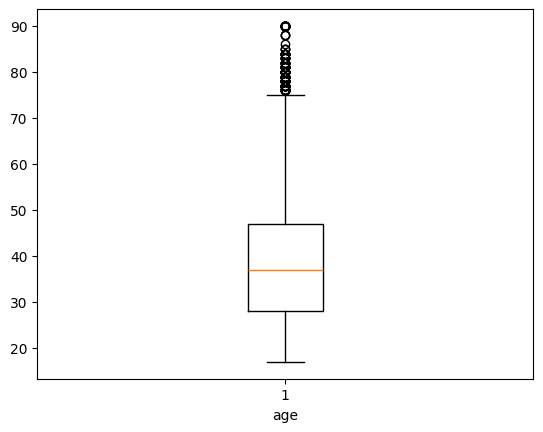

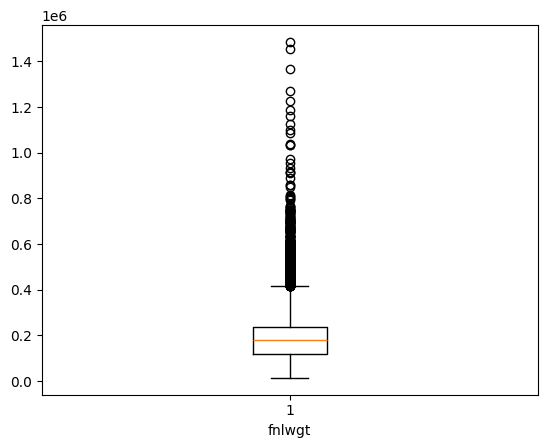

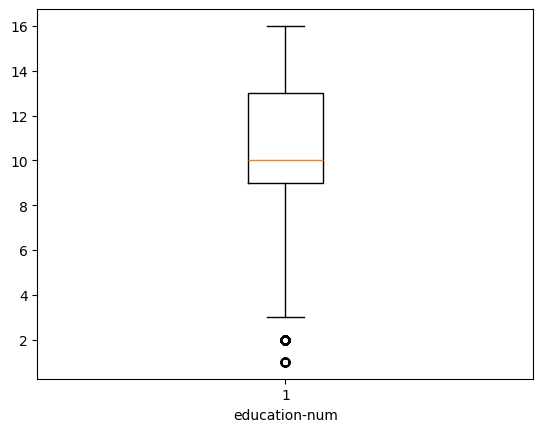

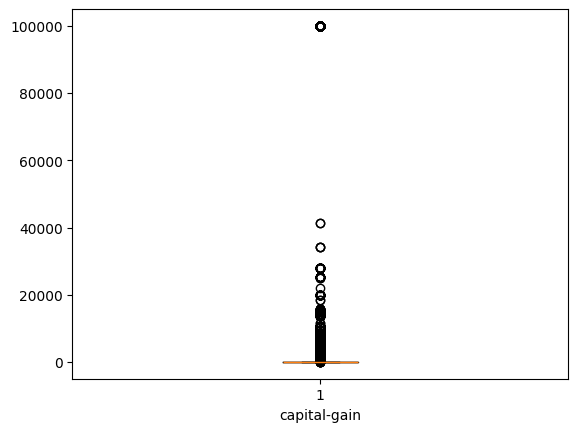

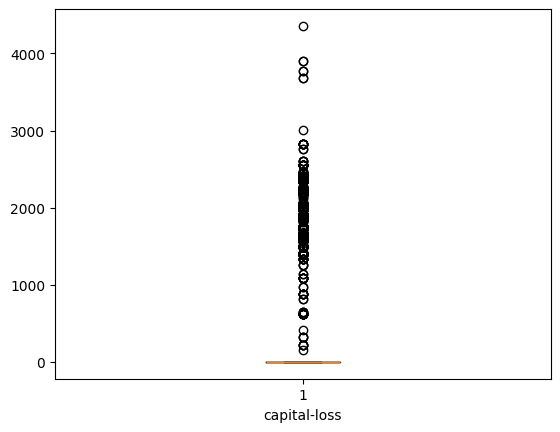

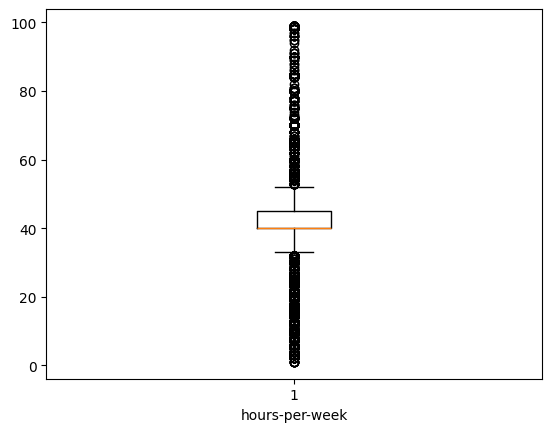

In [ ]:
#Check for Outliers
for i in df.columns:
  if df[i].dtype!='object':
    plt.boxplot(df[i])
    plt.xlabel(i)
    plt.show()

- Census data naturally contains extreme values. So we don't remove them because they are important to our analysis.

We visualize the distribution of the target variable, `Income`, to check for class imbalance.

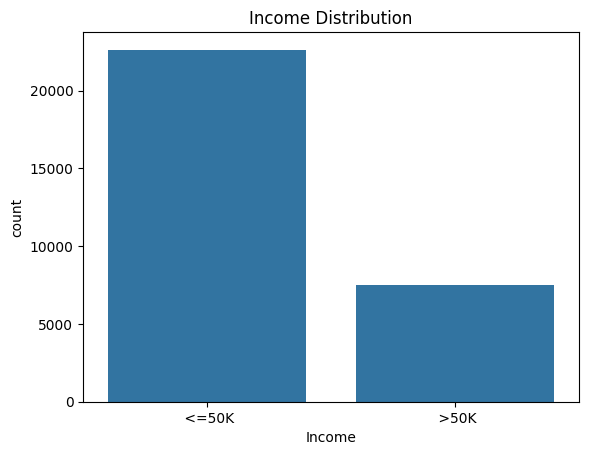

In [ ]:
sns.countplot(x=df['Income'])
plt.title('Income Distribution')
plt.show()

## **Insight:**

- More individuals earn <=50k than those who earn> 50k.

- This shows that my dataset is imbalanced.

We explore the relationship between `Age` and `Income` using a box plot.

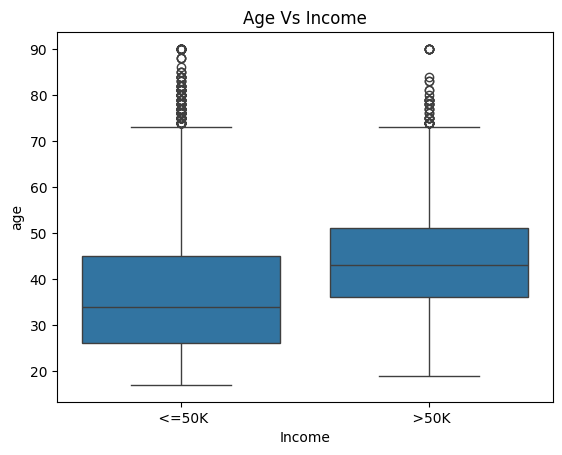

In [ ]:
sns.boxplot(x=df['Income'],y=df['age'])
plt.title('Age Vs Income')
plt.show()


- People earning >50K are generally older.

- This suggests that work experience is a major factor influencing income.

We analyze the relationship between `Education` levels and `Income` using a count plot.

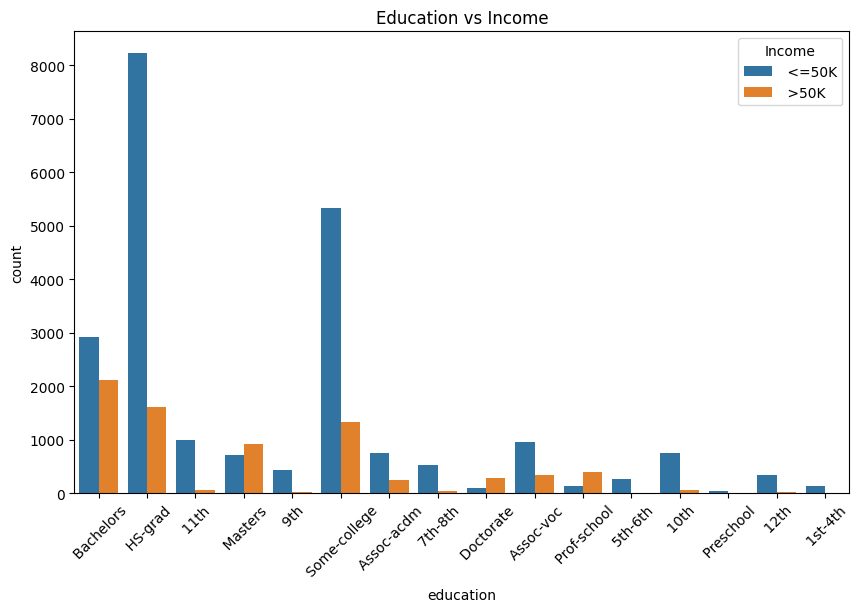

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(x=df['education'],hue=df['Income'])
plt.title('Education vs Income')
plt.xticks(rotation=45)
plt.show()

## 5. Data Preprocessing
This section involves preparing the data for machine learning models. This includes encoding categorical variables, splitting the data, handling class imbalance with SMOTE, and scaling numerical features.


- Higher Education levels(Master's, Doctorate, Prof. school) have more people earning >50k.

- Education is one of the strongest predictors of income.

We import `LabelEncoder` to convert categorical features into numerical representations.

In [ ]:
from sklearn.preprocessing import LabelEncoder

We apply Label Encoding to all `object` type columns in the DataFrame.

In [ ]:
le = LabelEncoder()

for i in df.columns:
  if df[i].dtypes == 'object':
    df[i]=le.fit_transform(df[i])

After encoding, we check the data types again to confirm all features are numerical.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30139 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             30139 non-null  int64
 1   workclass       30139 non-null  int64
 2   fnlwgt          30139 non-null  int64
 3   education       30139 non-null  int64
 4   education-num   30139 non-null  int64
 5   marital-status  30139 non-null  int64
 6   occupation      30139 non-null  int64
 7   relationship    30139 non-null  int64
 8   race            30139 non-null  int64
 9   sex             30139 non-null  int64
 10  capital-gain    30139 non-null  int64
 11  capital-loss    30139 non-null  int64
 12  hours-per-week  30139 non-null  int64
 13  native-country  30139 non-null  int64
 14  Income          30139 non-null  int64
dtypes: int64(15)
memory usage: 3.7 MB


We separate the features (`x`) from the target variable (`y`).

In [ ]:
x = df.drop('Income',axis=1)
y = df['Income']

We import `train_test_split` to divide the dataset into training and testing sets.

In [ ]:
from sklearn.model_selection import train_test_split

The data is split with a test size of 20% and a fixed `random_state` for reproducibility.

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

We examine the distribution of the target variable in the original dataset to confirm imbalance.

In [ ]:
y.value_counts()

,count
Income,
0,22633
1,7506


We import `SMOTE` to address the class imbalance by oversampling the minority class in the training data.

In [ ]:
from imblearn.over_sampling import SMOTE

SMOTE is applied to the training set (`x_train`, `y_train`).

In [ ]:
sm=SMOTE()
x_train,y_train=sm.fit_resample(x_train,y_train)

We import `StandardScaler` to normalize the numerical features, ensuring all features contribute equally to the model training.

In [ ]:
from sklearn.preprocessing import StandardScaler

The scaler is fitted on the training data and then used to transform both the training and test sets.

In [ ]:
scale = StandardScaler()
x_train = scale.fit_transform(x_train)
x_test = scale.transform(x_test)

## 5. Model Training and Evaluation
In this section, we train three different classification models (Logistic Regression, Decision Tree, and Random Forest) and evaluate their performance using various metrics.

In [ ]:
from sklearn.linear_model import LogisticRegression

### 5.1 Logistic Regression
We train a Logistic Regression model and make predictions on the test set.

In [ ]:
lr = LogisticRegression()
lr.fit(x_train,y_train)

LogisticRegression()

We calculate the accuracy, confusion matrix, and classification report for the Logistic Regression model.

In [ ]:
lr_pred = lr.predict(x_test)

The accuracy score for the Logistic Regression model.

In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [ ]:
lr_acc=accuracy_score(y_test,lr_pred)

The confusion matrix for Logistic Regression, showing true positives, true negatives, false positives, and false negatives.

In [ ]:
lr_con = confusion_matrix(y_test,lr_pred)

The classification report provides precision, recall, and F1-score for each class.

In [ ]:
lr_clr = classification_report(y_test,lr_pred)

Printing all evaluation metrics for Logistic Regression.

In [ ]:
print(lr_acc)
print(lr_con)
print(lr_clr)

0.772229595222296
[[3469 1016]
 [ 357 1186]]
              precision    recall  f1-score   support

           0       0.91      0.77      0.83      4485
           1       0.54      0.77      0.63      1543

    accuracy                           0.77      6028
   macro avg       0.72      0.77      0.73      6028
weighted avg       0.81      0.77      0.78      6028



### 5.2 Decision Tree Classifier
We train a Decision Tree Classifier and make predictions.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

The Decision Tree model is initialized with a maximum depth to prevent overfitting.

In [ ]:
dt=DecisionTreeClassifier(max_depth=8,random_state=12)
dt.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=8, random_state=12)

Predictions are made on the test set.

In [ ]:
dt_pred=dt.predict(x_test)

We calculate the accuracy for the Decision Tree model.

In [ ]:
dt_acc=accuracy_score(y_test,dt_pred)

The confusion matrix for the Decision Tree model.

In [ ]:
dt_con = confusion_matrix(y_test,dt_pred)

The classification report for the Decision Tree model.

In [ ]:
dt_clr = classification_report(y_test,dt_pred)

Printing all evaluation metrics for the Decision Tree Classifier.

In [ ]:
print(dt_acc)
print(dt_con)
print(dt_clr)

0.8044127405441274
[[3573  912]
 [ 267 1276]]
              precision    recall  f1-score   support

           0       0.93      0.80      0.86      4485
           1       0.58      0.83      0.68      1543

    accuracy                           0.80      6028
   macro avg       0.76      0.81      0.77      6028
weighted avg       0.84      0.80      0.81      6028



### 5.3 Random Forest Classifier
We train a Random Forest Classifier and make predictions.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

The Random Forest model is initialized with `class_weight='balanced'` to handle imbalance and `n_estimators` for the number of trees.

In [ ]:
rf=RandomForestClassifier(class_weight='balanced',n_estimators=50,random_state=23)
rf.fit(x_train,y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=50,
                       random_state=23)

Predictions are made on the test set.

In [ ]:
rf_pred=rf.predict(x_test)

We calculate the accuracy for the Random Forest model.

In [ ]:
rf_acc = accuracy_score(y_test,rf_pred)

The confusion matrix for the Random Forest model.

In [ ]:
rf_con = confusion_matrix(y_test,rf_pred)

The classification report for the Random Forest model.

In [ ]:
rf_clr = classification_report(y_test,rf_pred)

Printing all evaluation metrics for the Random Forest Classifier.

In [ ]:
print(rf_acc)
print(rf_con)
print(rf_clr)

0.8467153284671532
[[4041  444]
 [ 480 1063]]
              precision    recall  f1-score   support

           0       0.89      0.90      0.90      4485
           1       0.71      0.69      0.70      1543

    accuracy                           0.85      6028
   macro avg       0.80      0.79      0.80      6028
weighted avg       0.85      0.85      0.85      6028



## Conclusion
Based on the evaluation metrics (accuracy, confusion matrix, and classification report), the **Random Forest Classifier** demonstrated the best overall performance among the three models tested (Logistic Regression, Decision Tree Classifier, and Random Forest Classifier).

Specifically:
*   **Random Forest** achieved the highest accuracy of **84.67%**.
*   Its classification report showed a good balance of precision and recall for both classes, especially considering the initial class imbalance that was addressed through SMOTE. The F1-score for the positive class ('>50K') was also higher with Random Forest (0.70) compared to Logistic Regression (0.63) and Decision Tree (0.68).

Therefore, the Random Forest Classifier is the recommended model for predicting income in this dataset.